# Supplementary Figure S7a. Genome-wide colocalization patterns across six QTL layers

UpSet plot of all independent colocalized loci (CoS) detected genome-wide, before any support filter. Each locus is marked by the layers it colocalizes with: *cis*-eQTL, *trans*-eGene, *trans*-eProgram, protein-QTL, glycoprotein-QTL and metabolite-QTL. Intersections are sorted by size; the right bars give the total number of loci per layer (164,160 loci in total; 15,435 *cis*-eQTL, 136,596 *trans*-eGene, 88,916 *trans*-eProgram, 26,923 protein-QTL, 29,808 glycoprotein-QTL, 3,057 metabolite-QTL loci). No statistical test is involved.

Input: `data/Figure_S7a_upset_all_loci.rds`.

In [1]:
suppressPackageStartupMessages({
  library(ggplot2)
  library(ComplexUpset)
})
upset_all <- readRDS("data/Figure_S7a_upset_all_loci.rds")
dim(upset_all)
colSums(upset_all[, -1])
head(upset_all)

[1] 164160      7

cis-eQTL      trans-eGene   trans-eProgram      protein-QTL 
           15435           136596            88916            26923 
  metabolite-QTL glycoprotein-QTL 
            3057            29808

,locus_id,cis-eQTL,trans-eGene,trans-eProgram,protein-QTL,metabolite-QTL,glycoprotein-QTL
,<chr>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>
1,ind_cos_1,TRUE,TRUE,FALSE,FALSE,FALSE,FALSE
2,ind_cos_2,TRUE,TRUE,TRUE,FALSE,FALSE,TRUE
3,ind_cos_3,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE
4,ind_cos_4,TRUE,TRUE,FALSE,FALSE,FALSE,FALSE
5,ind_cos_5,TRUE,TRUE,FALSE,FALSE,FALSE,FALSE
6,ind_cos_6,TRUE,TRUE,TRUE,TRUE,FALSE,FALSE


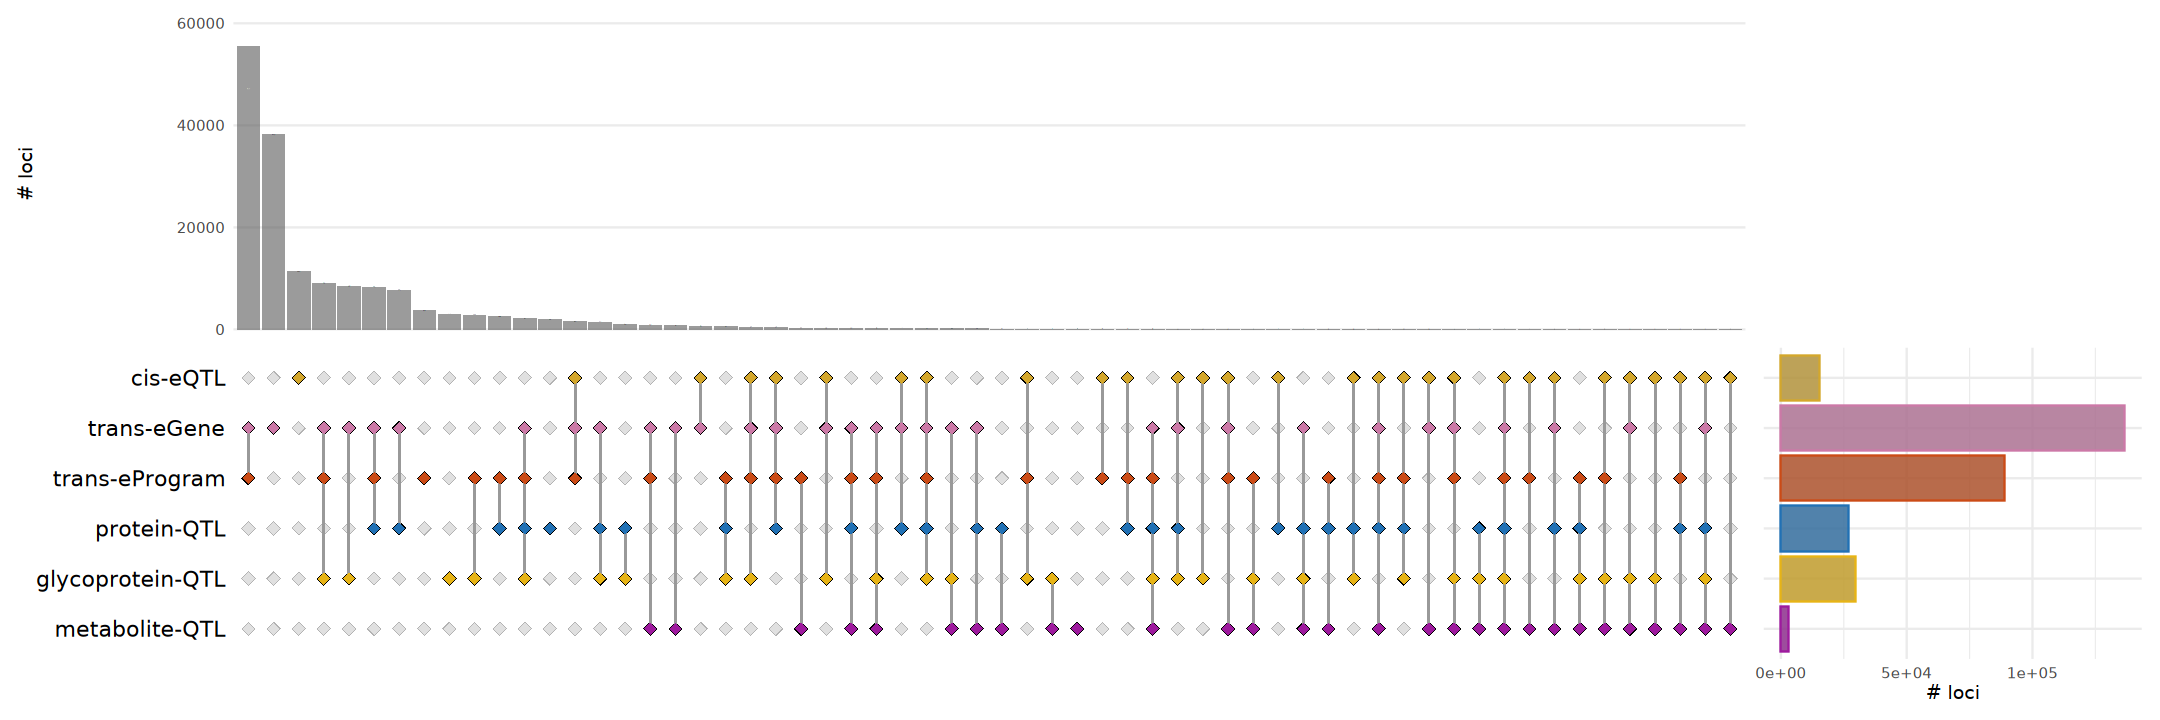

In [2]:
set_order  <- c("cis-eQTL", "trans-eGene", "trans-eProgram",
                "protein-QTL", "glycoprotein-QTL", "metabolite-QTL")
set_colors <- c("cis-eQTL" = "#D4A72C", "trans-eGene" = "#CC79A7", "trans-eProgram" = "#CB4B16",
                "protein-QTL" = "#2171B5", "glycoprotein-QTL" = "#E7B416", "metabolite-QTL" = "#9E1A9E")

p <- upset(
  upset_all, rev(set_order),
  name = NULL, width_ratio = 0.2, height_ratio = c(1, 1.6),
  sort_sets = FALSE, sort_intersections = "descending",
  queries = lapply(set_order, function(s) upset_query(set = s, fill = set_colors[[s]], color = set_colors[[s]])),
  set_sizes = upset_set_size(geom = geom_bar(alpha = 0.6), position = "right") +
    ylab("# loci"),
  base_annotations = list(
    "# loci" = intersection_size(text = list(size = 0), alpha = 0.6) +
      scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +
      theme(panel.grid.major.x = element_blank(), panel.grid.minor = element_blank())
  ),
  matrix = intersection_matrix(geom = geom_point(shape = 18, size = 3.5, stroke = 0),
                               segment = geom_segment(linewidth = 0.6, color = "grey60")) +
    scale_color_manual(values = c("TRUE" = "#2C3E50", "FALSE" = "#E0E0E0"), guide = "none"),
  stripes = upset_stripes(geom = geom_segment(linewidth = 0), colors = c("white", "white")),
  themes = upset_modify_themes(list(
    "intersections_matrix" = theme(axis.text.y = element_text(size = 13, color = "black"),
                                   panel.grid = element_blank())
  ))
)

options(repr.plot.width = 18, repr.plot.height = 6)
p